<a href="https://colab.research.google.com/github/KavyaPatel03/Amazon-Ecommerce-EDA/blob/main/Amazon_Ecommerce_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***PROJECT INTRODUCTION***

This Amazon E-Commerce Sales & Customer Behavior Analysis project focuses on transforming large-scale online transaction data into actionable business intelligence. Built using Python's data analysis stack (Pandas, NumPy, Seaborn, and Matplotlib), the project cleans and audits complex order logs, engineers temporal features, and examines granular purchasing patterns across time and geography.

This project Visualises day-of-week and hourly transaction cycles through aggregated heatmaps to identify high-conversion operational windows and off-peak periods.


In [1]:
# Importing the necessary liberaries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Loading the dataset
data = pd.read_csv('Amazon Data.csv', sep=',', on_bad_lines='skip', engine='python')

In [3]:
# Gathering the information about the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319522 entries, 0 to 319521
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   invoice_num   319522 non-null  int64  
 1   invoice_date  319522 non-null  object 
 2   year_month    319522 non-null  int64  
 3   month         319522 non-null  int64  
 4   day           319522 non-null  int64  
 5   hour          319522 non-null  int64  
 6   stock_code    319522 non-null  object 
 7   description   319522 non-null  object 
 8   quantity      319521 non-null  float64
 9   unit_price    319521 non-null  float64
 10  amount_spent  319521 non-null  float64
 11  cust_id       319521 non-null  float64
 12  country       319521 non-null  object 
dtypes: float64(4), int64(5), object(4)
memory usage: 31.7+ MB


In [4]:
# Understanding the details about the dataset
data.head(5)

,invoice_num,invoice_date,year_month,month,day,hour,stock_code,description,quantity,unit_price,amount_spent,cust_id,country
0,536365,01-12-2010 8.26,201012,12,3,8,85123A,white hanging heart t-light holder,6.0,2.55,15.30,17850.0,United Kingdom
1,536365,01-12-2010 8.26,201012,12,3,8,71053,white metal lantern,6.0,3.39,20.34,17850.0,United Kingdom
2,536365,01-12-2010 8.26,201012,12,3,8,84406B,cream cupid hearts coat hanger,8.0,2.75,22.00,17850.0,United Kingdom
3,536365,01-12-2010 8.26,201012,12,3,8,84029G,knitted union flag hot water bottle,6.0,3.39,20.34,17850.0,United Kingdom
4,536365,01-12-2010 8.26,201012,12,3,8,84029E,red woolly hottie white heart.,6.0,3.39,20.34,17850.0,United Kingdom


In [5]:
# Finding the null values in each column
data.isnull().sum()

,0
invoice_num,0
invoice_date,0
year_month,0
month,0
day,0
hour,0
stock_code,0
description,0
quantity,1
unit_price,1


In [6]:
# Changing the data type to string
data['year'] = data['year_month'].astype(str).str[:2]

Changing the data type to string and then removing the last 2 digits so that it gets converted into the year the transaction has been completed and then stored into a new column named year so that even if the data is gets messy,we can always access the real data.

In [7]:
# Changing the format of invoivce date and time
data['invoice_date'] = pd.to_datetime(data['invoice_date'], format='%d-%m-%Y %H.%M')
data['date'] = data['invoice_date'].dt.date
data['time'] = data['invoice_date'].dt.time

Changing the format of invoivce date and time for a clear presentation and then storing the date in a new column for a better analysis and conclusion and same as with storing the time in a different column.

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319522 entries, 0 to 319521
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   invoice_num   319522 non-null  int64         
 1   invoice_date  319522 non-null  datetime64[ns]
 2   year_month    319522 non-null  int64         
 3   month         319522 non-null  int64         
 4   day           319522 non-null  int64         
 5   hour          319522 non-null  int64         
 6   stock_code    319522 non-null  object        
 7   description   319522 non-null  object        
 8   quantity      319521 non-null  float64       
 9   unit_price    319521 non-null  float64       
 10  amount_spent  319521 non-null  float64       
 11  cust_id       319521 non-null  float64       
 12  country       319521 non-null  object        
 13  year          319522 non-null  object        
 14  date          319522 non-null  object        
 15  time          319

In [9]:
# Changing the month numbers to the month name
data['month_name'] = data['month'].map({1: 'January', 2: 'February', 3: 'March', 4: 'April',5: 'May', 6: 'June', 7: 'July', 8: 'August',9: 'September', 10: 'October', 11: 'November', 12: 'December'})

The changing of the month number to month name as it can cause a confusion between the no of days and the months as the number of days are also in numeric form.

In [10]:
# Changing the day numbers to the day name
data['day_name'] = data['day'].map({1:'Monday',2:'Tuesday',3:'Wednesday',4:'Thursday',5:'Friday', 7 :'Saturday'})

The changing of the day number to day name as it can cause a confusion between the no of days and the months as the months are also in numeric form.

In [11]:
# Changing the hour into AM and PM for easy interpretation
data['hour_1'] = data['hour'].map({ 6: '6:00 AM',7: '7:00 AM',8: '8:00 AM',9: '9:00 AM',10: '10:00 AM',11: '11:00 AM',12: '12:00 PM',13: '1:00 PM',14: '2:00 PM',15: '3:00 PM',16: '4:00 PM',17: '5:00 PM',18: '6:00 PM',19: '7:00 PM',20: '8:00 PM'})

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319522 entries, 0 to 319521
Data columns (total 19 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   invoice_num   319522 non-null  int64         
 1   invoice_date  319522 non-null  datetime64[ns]
 2   year_month    319522 non-null  int64         
 3   month         319522 non-null  int64         
 4   day           319522 non-null  int64         
 5   hour          319522 non-null  int64         
 6   stock_code    319522 non-null  object        
 7   description   319522 non-null  object        
 8   quantity      319521 non-null  float64       
 9   unit_price    319521 non-null  float64       
 10  amount_spent  319521 non-null  float64       
 11  cust_id       319521 non-null  float64       
 12  country       319521 non-null  object        
 13  year          319522 non-null  object        
 14  date          319522 non-null  object        
 15  time          319

In [13]:
print('The TOP 5 customers with highest money spent...')
data.sort_values(by='amount_spent', ascending=False).head(5)

The TOP 5 customers with highest money spent...


,invoice_num,invoice_date,year_month,month,day,hour,stock_code,description,quantity,unit_price,amount_spent,cust_id,country,year,date,time,month_name,day_name,hour_1
37126,541431,2011-01-18 10:01:00,201101,1,2,10,23166,medium ceramic top storage jar,74215.0,1.04,77183.60,12346.0,United Kingdom,20,2011-01-18,10:01:00,January,Tuesday,10:00 AM
155418,556444,2011-06-10 15:28:00,201106,6,5,15,22502,picnic basket wicker 60 pieces,60.0,649.50,38970.00,15098.0,United Kingdom,20,2011-06-10,15:28:00,June,Friday,3:00 PM
118352,551697,2011-05-03 13:46:00,201105,5,2,13,POST,postage,1.0,8142.75,8142.75,16029.0,United Kingdom,20,2011-05-03,13:46:00,May,Tuesday,1:00 PM
248706,567423,2011-09-20 11:05:00,201109,9,2,11,23243,set of tea coffee sugar tins pantry,1412.0,5.06,7144.72,17450.0,United Kingdom,20,2011-09-20,11:05:00,September,Tuesday,11:00 AM
32732,540815,2011-01-11 12:55:00,201101,1,2,12,21108,fairy cake flannel assorted colour,3114.0,2.10,6539.40,15749.0,United Kingdom,20,2011-01-11,12:55:00,January,Tuesday,12:00 PM


Finding the top 5 customers with the highest amount spent by them in total.

This reveals a little pattern about those customers that when they are making purchases and what is the average amount spent by them on each order or when they will require the same product again after a specific time of use.

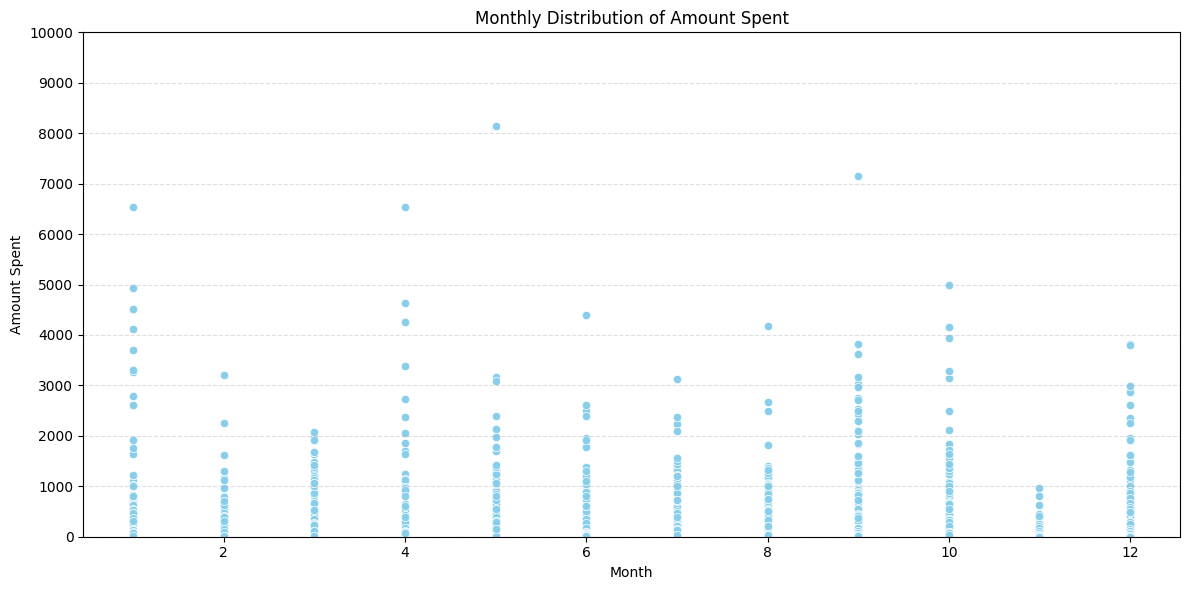

In [14]:
# Shows the Monthly distribution of amount spent by a scatter chart
plt.figure(figsize=(12, 6))

sns.scatterplot(data=data,x='month',y='amount_spent',color='skyblue')
plt.ylim(0, 10000)
plt.yticks(range(0,10001, 1000))
plt.title('Monthly Distribution of Amount Spent')
plt.xlabel('Month')
plt.ylabel('Amount Spent')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


This is a scatter chart which shows the amount spent by the public on amazon on each months.

According to this chart the major amount of purchases happened is during the month of October to December as the dataset contains the data of the abroad market and according to the calender, they have major amount of festivals like Halloween and the Christmas in which they tend to give and receive presents.

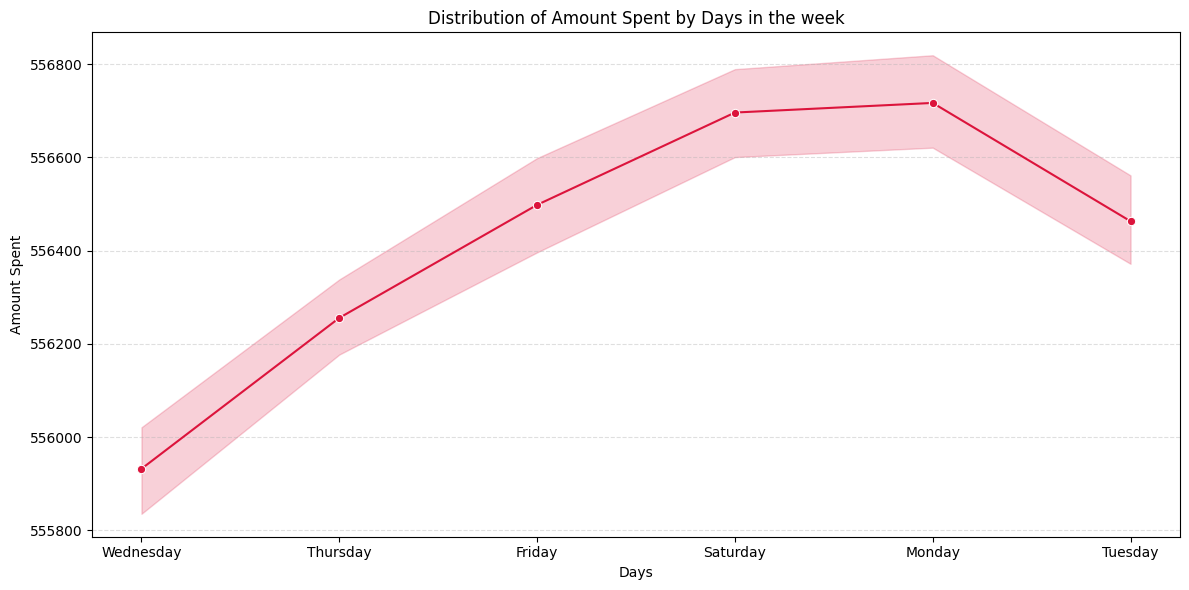

In [34]:
# Shows the Distribution of amount spent by days in the week by a line chart
plt.figure(figsize=(12, 6))

sns.lineplot(data=data,x='day_name',y='invoice_num',color='crimson',marker = 'o')

plt.title('Distribution of Amount Spent by Days in the week')
plt.xlabel('Days')
plt.ylabel('Amount Spent')
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


This is a line chart which shows the amount spent by the public on amazon on the days of the week.

According to this chart, the highest amount is spent on saturday as there can be a pattern behind this chart.Most of the people have holidays for the weekend and they try to get the things that are required for the week on the weekends and hence the result is obvious that public has spent the highest on the weekends.

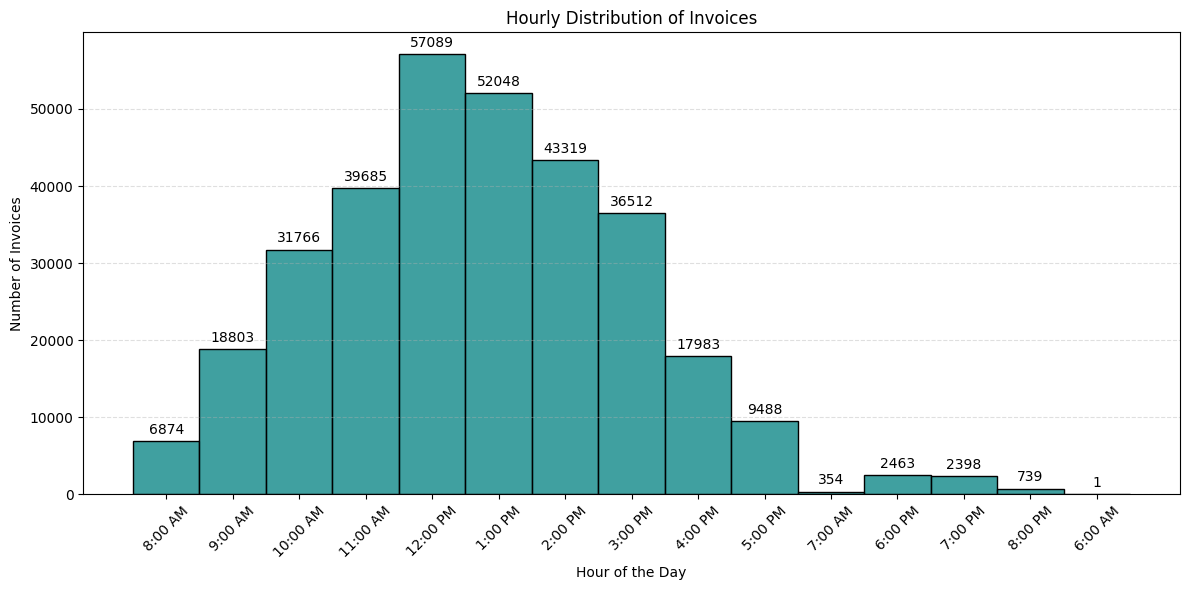

In [16]:
#Shows the hourly distribution of invoices by a histogram

plt.figure(figsize=(12, 6))

ax = sns.histplot(bins=50, data=data, x='hour_1', color='teal')

plt.title('Hourly Distribution of Invoices')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)
ax.bar_label(ax.containers[0], padding=3, fontsize=10)

plt.tight_layout()
plt.show()

This is a histogram which shows the total number of invoices made in each hour of the day.

According to this chart, the major amount of sales happen during 10:00 AM to 3:00 PM.The major reason of the sales is this high is because most of the purchasing is been done by the females of the house and they mostly gets free around this hour of the day.

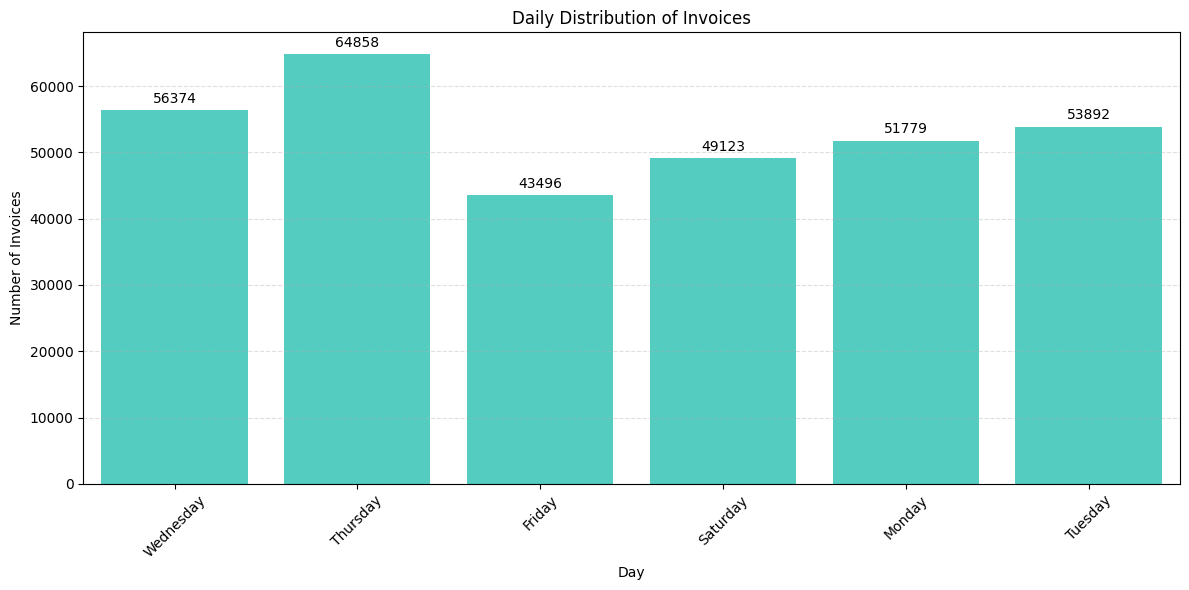

In [17]:
# Shows the daily distribution of the invoices by a Count plot

plt.figure(figsize=(12, 6))

ax = sns.countplot( data=data, x='day_name', color='turquoise')

plt.title('Daily Distribution of Invoices')
plt.xlabel('Day')
plt.ylabel('Number of Invoices')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)
ax.bar_label(ax.containers[0], padding=3, fontsize=10)

plt.tight_layout()
plt.show()

This is a Count plot which shows the total number of invoices made in each day.

It is not correct to assume that the higher the number of invoices the higher the sale would be on that day as the invoices can be of different values and quantities.

We can see that on saturday they have the most amount of sales on an average according to the previous line chart but according to this count plot we have more number of invoices on Thursday.

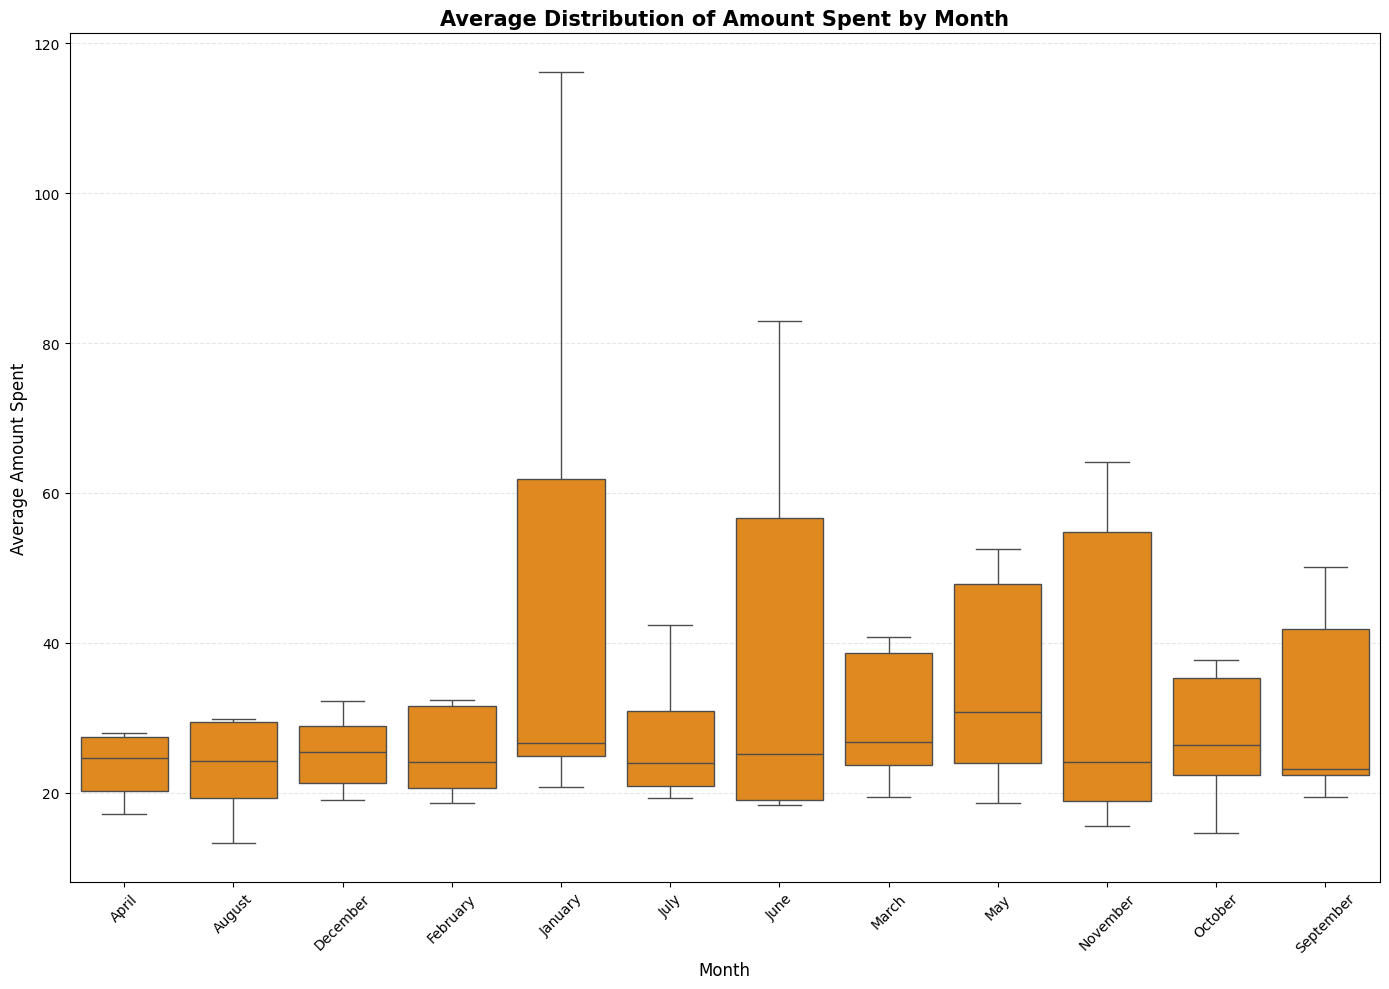

In [18]:
# Select the top 10 countries by number of records
top_countries = data['country'].value_counts().head(10).index

plot_data = data[data['country'].isin(top_countries)]

avg_data = plot_data.groupby(['month_name', 'country'], observed=True)['amount_spent'].mean().reset_index()

plt.figure(figsize=(14, 10))

sns.boxplot(data=avg_data,x='month_name',y='amount_spent',color='darkorange',showfliers=False)

plt.title('Average Distribution of Amount Spent by Month',fontsize=15, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Amount Spent', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

This is a box plot which shows the average amount spent in each month by the public ignoring the outliers.

The average amount spent in each month lies between 20 - 30 dollars and we can conclude that from the line between the box and by the end of the whiskers as the show the range of the data.

Majority of the boxes lies between amount 20 - 40 dollars range because the data is spreaded very less and have a very small amount of outliers.

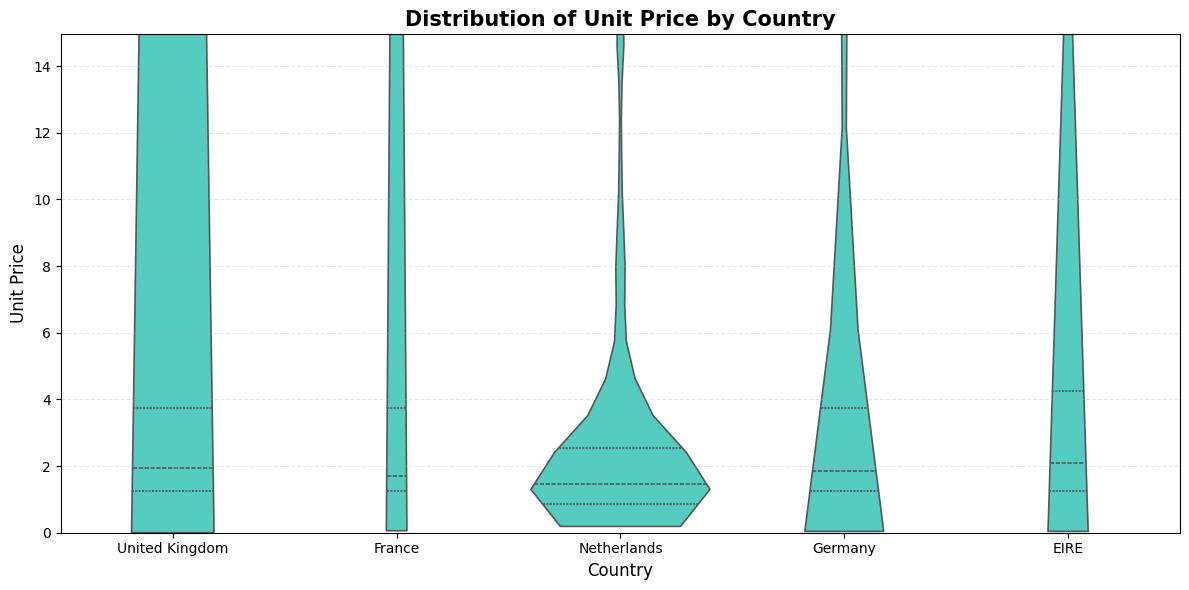

In [19]:
# Select the top 5 countries by number of records
top_countries = data['country'].value_counts().head(5).index

plot_data = data[
    data['country'].isin(top_countries) &
    (data['unit_price'] > 0)]

plt.figure(figsize=(12, 6))

sns.violinplot(data=plot_data,x='country',y='unit_price',color='turquoise',inner='quartile',cut=0,linewidth=1.2)

plt.title('Distribution of Unit Price by Country',fontsize=15, fontweight='bold')
plt.xlabel('Country', fontsize=12)
plt.ylabel('Unit Price', fontsize=12)

plt.ylim(0, plot_data['unit_price'].quantile(0.99))
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

This is a violin plot which shows the distribution of unit price by the top 5 countries which has the highest number of records.

Most of the countries have a large baseline and it starts to get narrower as it goes above and the widthness shows the spread of the data.

We can see that United Kingdom has the least amount of change in spread as we go above the chart whereas in France we can see that it has the least amount of spread in the data at the baseline of the chart.

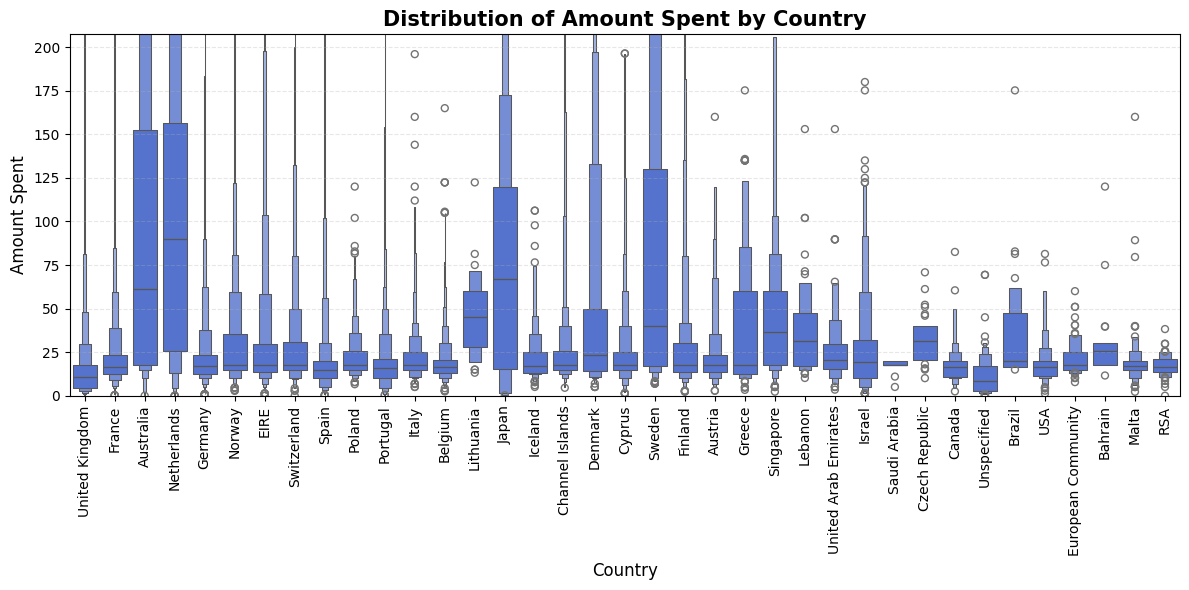

In [25]:
# Shows the Distribution of Amount Spent by Country by a boxen plot
plt.figure(figsize=(12, 6))

sns.boxenplot(data=data,x='country',y='amount_spent',color='royalblue')

plt.title('Distribution of Amount Spent by Country',fontsize=15, fontweight='bold')
plt.xlabel('Country', fontsize=12)
plt.ylabel('Amount Spent', fontsize=12)

plt.ylim(0, data['amount_spent'].quantile(0.99))
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

This is a boxen plot which shows the distribution of amount spent by the countries.

The difference between box plot and boxen plot is that the box plot does not show the spread of the data whereas the boxen plot shows the spread of the data.

The countries like Australia , Netherlands , Japan and Sweden have the highest overall spending distributions.

The countries like UK and France shows that they are highly consistent as it has the most amount of spread near the boxes.

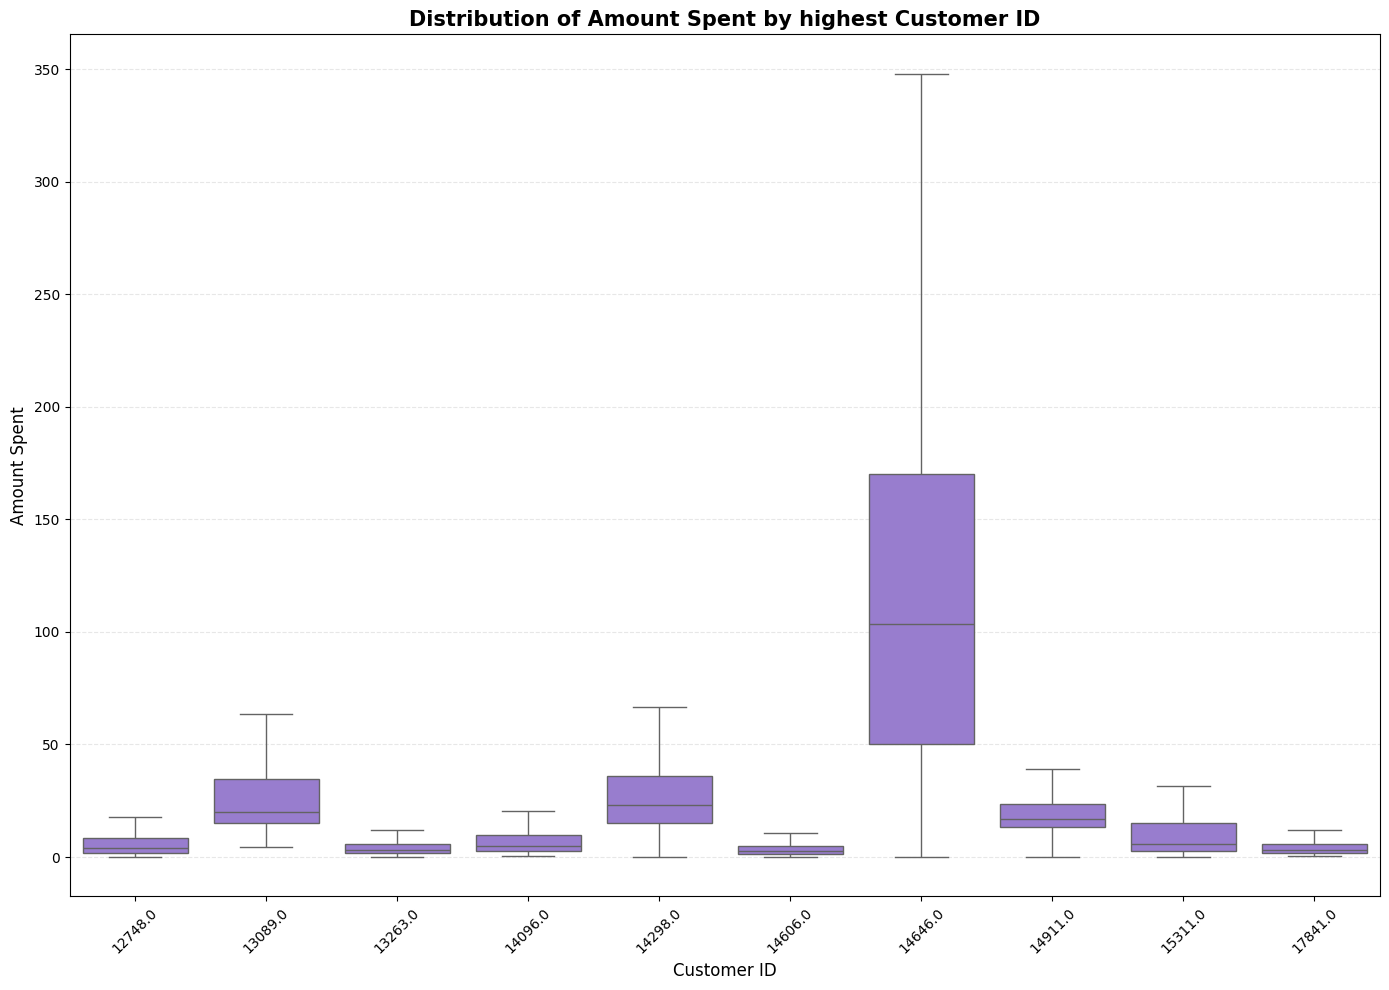

In [26]:
# Shows the Distribution of Amount Spent by highest Customer ID by a box plot
highest_customer = data['cust_id'].value_counts().head(10).index

plot_data = data[data['cust_id'].isin(highest_customer)]

plt.figure(figsize=(14, 10))

sns.boxplot(
    data=plot_data,
    x='cust_id',
    y='amount_spent',
    color='mediumpurple',
    showfliers=False
)

plt.title('Distribution of Amount Spent by highest Customer ID',
          fontsize=15, fontweight='bold')
plt.xlabel('Customer ID', fontsize=12)
plt.ylabel('Amount Spent', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

This is a box plot which shows the top 10 highest spending customer IDs.

This chart can be useful by giving attractive offers to the customers who tend to spend high amounts in purchase so that they stick to the platform and we can also give some discounts on conditional basis to attract one time users or low spenders.

There is an customer who has an average of $100 of spending as wll as we have customers who only spends an average of 5 - 7 dollars on every purchase.

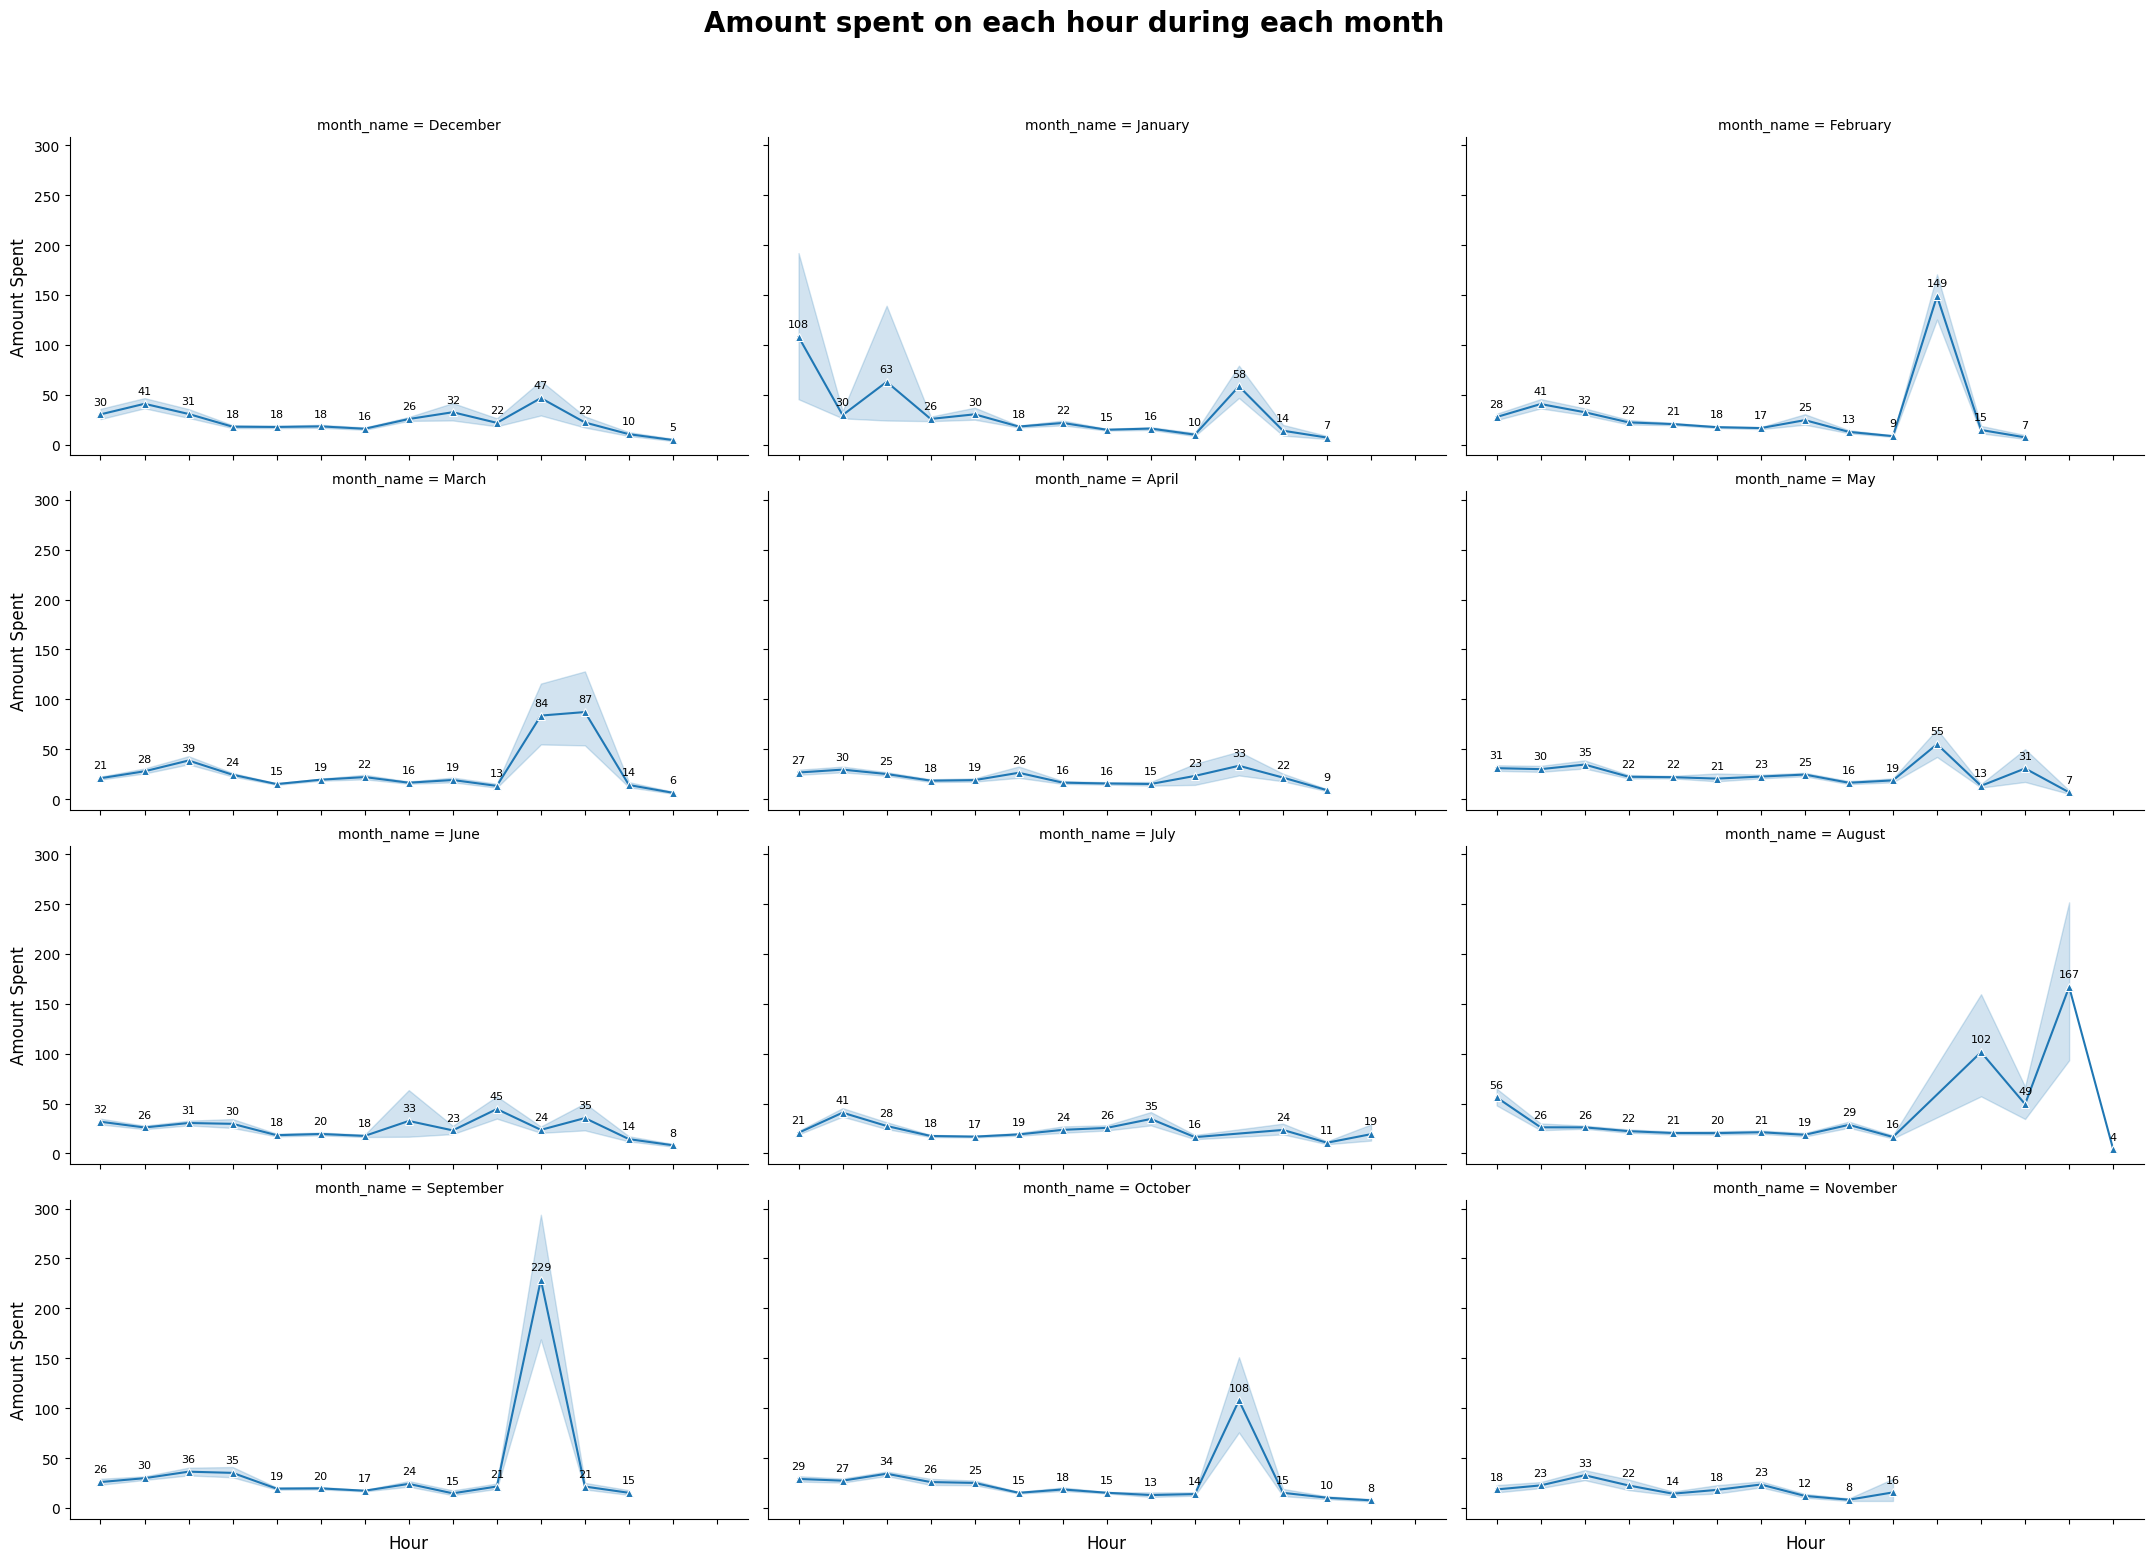

In [29]:
# Shows the Amount spent on each hour during each month with the help of subplots
g = sns.relplot(data=data,x="hour_1",y="amount_spent",col="month_name",col_wrap=3,kind="line",height=4,aspect=1.8,marker = '^')

g.set_xticklabels(rotation=45, ha="right")

for ax in g.axes.flat:
    for line in ax.lines:
        x_values = line.get_xdata()
        y_values = line.get_ydata()

        for x, y in zip(x_values, y_values):
            if not (x is None or y is None):
                ax.annotate(
                    f'{y:.0f}',
                    (x, y),
                    textcoords="offset points",
                    xytext=(0, 7),
                    ha='center',
                    fontsize=8)


g.set_axis_labels("Hour", "Amount Spent", fontsize=12)
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("Amount spent on each hour during each month ", fontsize=20,weight = 'bold')

plt.show()

This is a relplot where we can plot multiple charts together for an easier comparision of the data.

We can see a pattern around here that the sales gets a boost between noon and evening.

What we can do to boost some sales in the morning is that start some deals that are only available for a specfic time of the day like from morning 8:00 AM to 11:00 AM on the products that are required for the mrning use like toothbrushes and toothpastes , bread , milk , cereals and many different daily usable things.

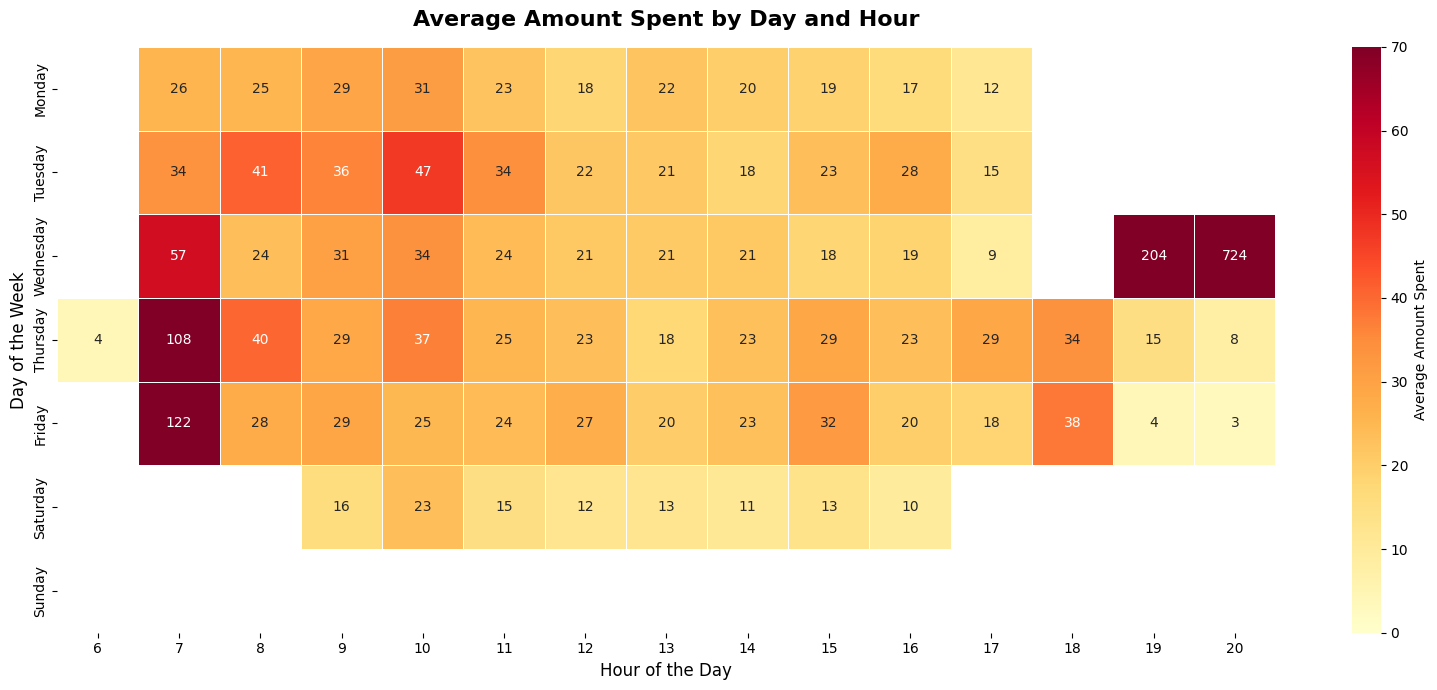

In [37]:
# Shows the Average Amount Spent by Day and Hour through a heat map
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

heatmap_data = data.pivot_table(index='day_name',columns='hour',values='amount_spent',aggfunc='mean')

heatmap_data = heatmap_data.reindex(day_order)
heatmap_data = heatmap_data.reindex(sorted(heatmap_data.columns), axis=1)

plt.figure(figsize=(16, 7))

sns.heatmap(heatmap_data,cmap='YlOrRd',annot=True,fmt='.0f',linewidths=0.5,linecolor='white',vmin=0,vmax=70,cbar_kws={'label': 'Average Amount Spent'})

plt.title('Average Amount Spent by Day and Hour', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Hour of the Day', fontsize=12)
plt.ylabel('Day of the Week', fontsize=12)

plt.tight_layout()
plt.show()

This heatmap shows the amount of sales according to each day on each hour of the day.

We can see that tuesday has the most consistent sales from all the days.

We see some sudden spikes like on Wednesday even after the sales of 204 on 7:00 PM ,the sales sky rocketed to 724 on 8:00 PM and on Thursday the sales went from 4 to 108 on 7:00 AM.